In [2]:
%pip install tensorflow numpy matplotlib scikit-learn

   ---------------------------------------- 0.0/351.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/351.2 MB ? eta -:--:--
   ---------------------------------------- 0.5/351.2 MB 1.7 MB/s eta 0:03:32
   ---------------------------------------- 1.0/351.2 MB 2.1 MB/s eta 0:02:46
   ---------------------------------------- 1.0/351.2 MB 2.1 MB/s eta 0:02:46
   ---------------------------------------- 1.3/351.2 MB 1.3 MB/s eta 0:04:27
   ---------------------------------------- 1.3/351.2 MB 1.3 MB/s eta 0:04:27
   ---------------------------------------- 1.3/351.2 MB 1.3 MB/s eta 0:04:27
   ---------------------------------------- 1.8/351.2 MB 1.1 MB/s eta 0:05:19
   ---------------------------------------- 1.8/351.2 MB 1.1 MB/s eta 0:05:19
   ---------------------------------------- 2.4/351.2 MB 1.1 MB/s eta 0:05:06
   ---------------------------------------- 3.1/351.2 MB 1.4 MB/s eta 0:04:10
   ---------------------------------------- 3.7/351.2 MB 1.5 MB/s eta 0:03:47


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
streamlit 1.51.0 requires protobuf<7,>=3.20, but you have protobuf 7.36.2 which is incompatible.


Training samples: 25000
Testing samples: 25000


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 200, 64)        │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d_1      │ (None, 64)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 644,225 (2.46 MB)

 Trainable params: 644,225 (2.46 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 10s 42ms/step - accuracy: 0.6795 - loss: 0.6126 - val_accuracy: 0.8154 - val_loss: 0.4475
Epoch 2/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.8464 - loss: 0.3665 - val_accuracy: 0.8596 - val_loss: 0.3369
Epoch 3/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 5s 32ms/step - accuracy: 0.8888 - loss: 0.2764 - val_accuracy: 0.8616 - val_loss: 0.3292
Epoch 4/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 7s 44ms/step - accuracy: 0.9071 - loss: 0.2397 - val_accuracy: 0.8708 - val_loss: 0.3178
Epoch 5/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 6s 36ms/step - accuracy: 0.9155 - loss: 0.2205 - val_accuracy: 0.8602 - val_loss: 0.3433
Test Loss: 0.385
Test Accuracy: 83.55 %


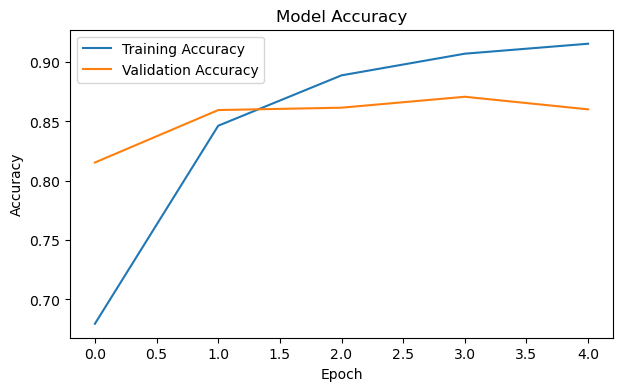

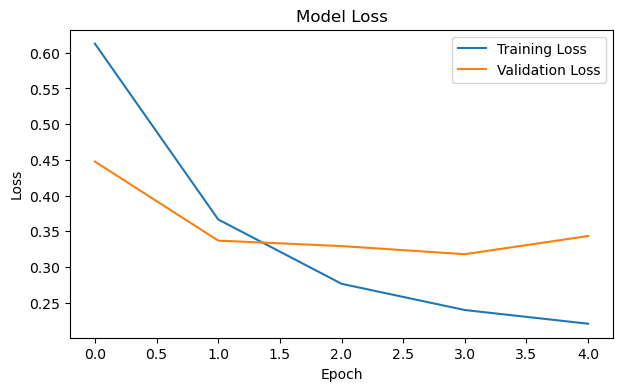


Classification Report:
              precision    recall  f1-score   support

    Negative       0.79      0.91      0.85     12500
    Positive       0.90      0.76      0.82     12500

    accuracy                           0.84     25000
   macro avg       0.84      0.84      0.83     25000
weighted avg       0.84      0.84      0.83     25000



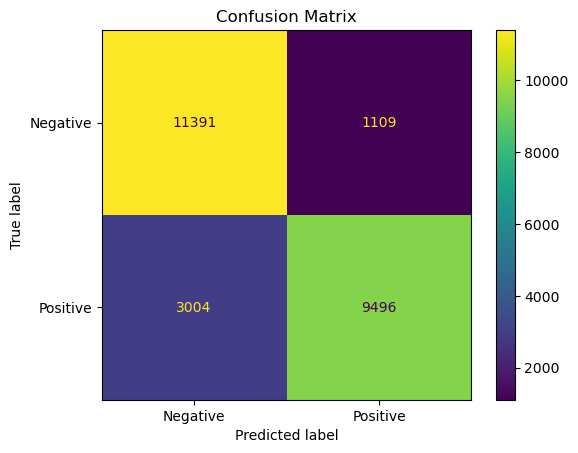

Model saved successfully!


In [4]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.preprocessing.sequence import pad_sequences

from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# 1. Load the movie review dataset
vocab_size = 10000
max_length = 200

(x_train, y_train), (x_test, y_test) = (
    keras.datasets.imdb.load_data(num_words=vocab_size)
)

print("Training samples:", len(x_train))
print("Testing samples:", len(x_test))

# 2. Prepare the data
x_train = pad_sequences(
    x_train, maxlen=max_length, padding="post", truncating="post"
)
x_test = pad_sequences(
    x_test, maxlen=max_length, padding="post", truncating="post"
)

# 3. Build the deep learning model
model = keras.Sequential([
    layers.Input(shape=(max_length,)),
    layers.Embedding(vocab_size, 64),
    layers.GlobalAveragePooling1D(),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(1, activation="sigmoid")
])

# 4. Compile the model
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

# 5. Train the model
history = model.fit(
    x_train,
    y_train,
    epochs=5,
    batch_size=128,
    validation_split=0.2
)

# 6. Evaluate the model
loss, accuracy = model.evaluate(x_test, y_test, verbose=0)

print("Test Loss:", round(loss, 4))
print("Test Accuracy:", round(accuracy * 100, 2), "%")

# 7. Plot training and validation accuracy
plt.figure(figsize=(7, 4))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

# 8. Plot training and validation loss
plt.figure(figsize=(7, 4))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

# 9. Generate predictions and evaluation metrics
probabilities = model.predict(x_test, verbose=0).ravel()
predictions = (probabilities >= 0.5).astype(int)

print("\nClassification Report:")
print(classification_report(
    y_test,
    predictions,
    target_names=["Negative", "Positive"]
))

# 10. Display the confusion matrix
cm = confusion_matrix(y_test, predictions)
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Positive"]
)
display.plot()
plt.title("Confusion Matrix")
plt.show()

# 11. Save the trained model
model.save("sentiment_classifier.keras")

print("Model saved successfully!")